# Introduction and Objective

In this project, we design a **Team Allocation Algorhithm**.

The goal is to automatically assign students into fair and balanced project teams based on three key criteria:

1. **School Diversity** – No majority from the same school to ensure varied skill sets.  
2. **Gender Balance** – To promote gender diversity, no teams should have a majority of students from the same gender  
3. **Academic Balance** – CGPA distribution should prevent teams from being too strong or too weak academically.  

The program processes a CSV file of student records, applies the fairness constraints, and exports a new CSV containing the final team assignments.

**Computational Thinking (CT) Principles Applied**
- **Decomposition** – Splitting the problem into smaller sub-tasks: data reading, grouping, constraint checking, and reporting.  
- **Abstraction** – Representing each student as a dictionary with essential attributes.  
- **Pattern Recognition** – Recognising similarities in gender, school, and CGPA trends.  
- **Algorithmic Thinking** – Designing logical, rule-based steps to create fair groupings.


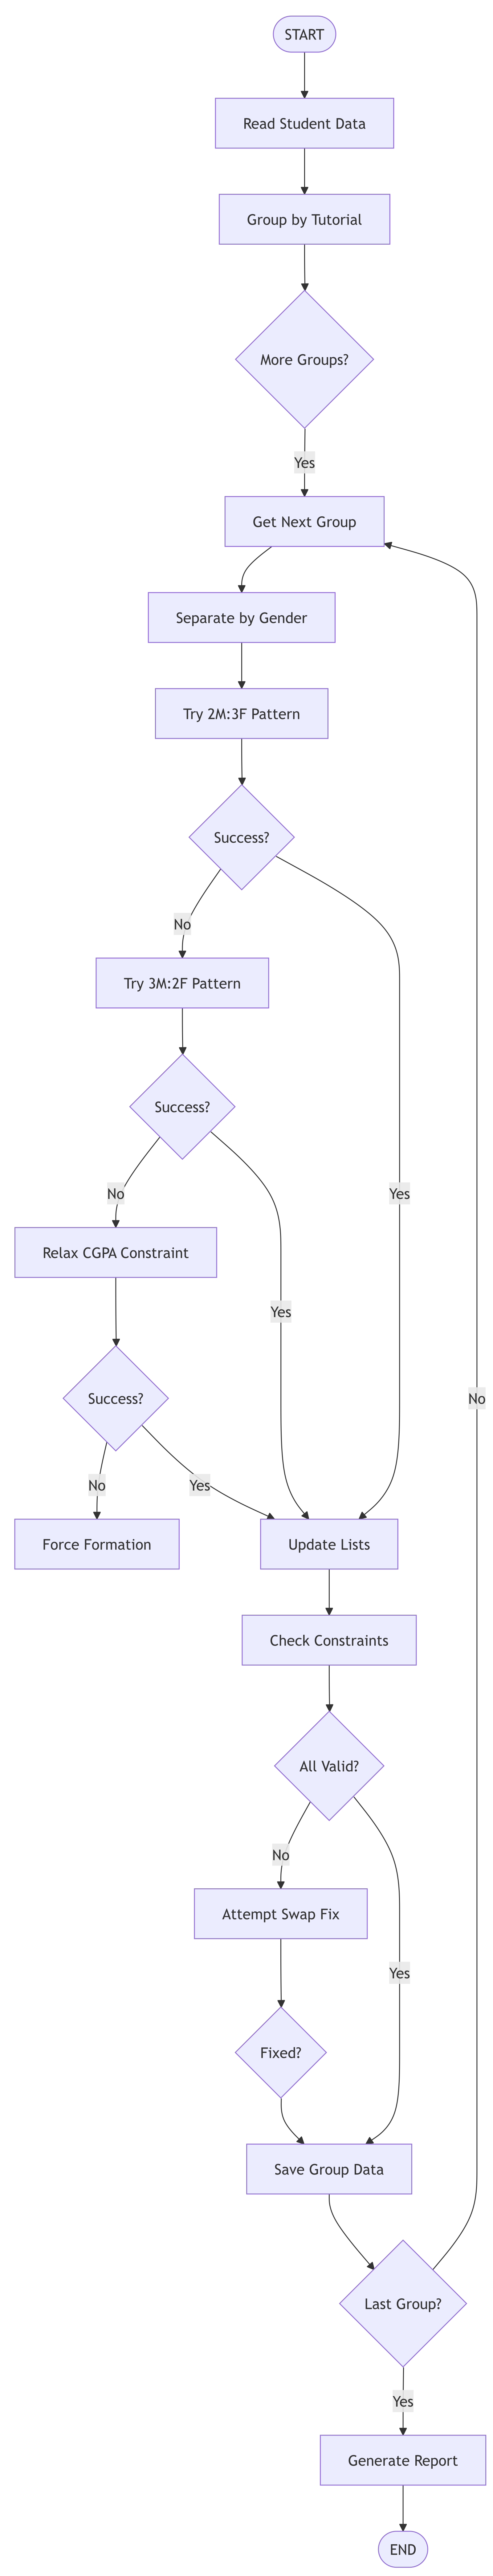

In [2]:
import base64
from IPython.display import Markdown


with open("/Users/yunyili/Downloads/flowchart5.jpg", "rb") as f:
    img_base64 = base64.b64encode(f.read()).decode()


md = f"![flowchart](data:image/jpeg;base64,{img_base64})"
display(Markdown(md))

In [1]:
## Section 1: Imports and Setup

## Importing necessary Python modules

import csv ## read and write CSV files containing student data
from collections import Counter, defaultdict  ## count occurrences of items such as gender or school, automatically create lists for tutorial groups
import random  ## perform random swaps when attempting to fix constraint violations


## Data Reading and Preprocessing

The first stage of the algorithm focuses on preparing and structuring the data.  
Two main tasks are performed here:

1. **Categorizing CGPA values** –   Having analysed the data given, we have noticed that a majority of students' CGPA fall within the range 4.0-4.15. Hence, we have designated this range to be the average, while anything below is 'low' and anything above is 'high'.
2. **Reading CSV records** – The data from `records.csv` is imported and converted into a list of dictionaries, where each dictionary represents a student with fields such as Tutorial Group, Student ID, Name, School, Gender, and CGPA.

**Computational Thinking (CT) Principles Applied**
- **Abstraction:** Simplifying continuous CGPA values into categories for easier comparison.  
- **Decomposition:** Separating the preprocessing step into two smaller, manageable functions (`cgpa_range()` and `read_students()`).  


In [2]:
## Section 2: Data Reading and Preprocessing

def cgpa_range(cgpa):## classifies each student's CGPA into one of three categories and 
                    ## help maintain academic diversity when forming project teams later in the algorithm.
    
    ## Defined conditions for each category
    if 3.7 < cgpa <= 4.0:
        return 'low'
    elif 4.0 < cgpa <= 4.15:
        return 'medium'
    elif cgpa > 4.15:
        return 'high'
    else:
        return None



def readstudents(filename): ## reads the student data from the provided CSV file
    students = [] ## each row in the file is converted into a dictionary for easy access to specific attributes such as gender, school, or CGPA.
    with open(filename) as file:
        reader = csv.DictReader(file)
        for x in reader: ## iterate through each row and preprocess CGPA
            x['CGPA'] = float(x['CGPA']) 
            x['CGPA_range'] = cgpa_range(x['CGPA']) ## categorize CGPA
            students.append(x)
    return students


# Grouping and Constraint Checking

After reading and preprocessing the student data, the next step is to group students by their **tutorial groups** and to check whether each team meets the fairness rules.  


### Function: group_by_tutorial()
This function groups all students into their respective tutorial groups.
Each key in the dictionary corresponds to one tutorial group (e.g., 'G1'), and the value is a list of all student dictionaries belonging to that group.

**CT Concepts Applied**
- **Decomposition:** Separates the task of grouping students into smaller, logical steps.  
- **Abstraction:** Represents each tutorial group as a list of students under one key.  
- **Pattern Recognition:** Identifies common group structure (50 students per group).  
- **Algorithmic Thinking:** Uses dictionary-based grouping for efficient retrieval.


In [3]:
## Section 3: Grouping Students and Checking Constraints

def grp_with_tut(students):
    grps = defaultdict(list)
    for s in students:
        grps[s['Tutorial Group']].append(s)
    return grps 


### Function: check_constraints()
This function evaluates whether a team of 5 students satisfies all three fairness conditions:
1. Gender diversity – No more than 3 males or 3 females.  
2. School diversity – No more than 2 students from the same school.  
3. Academic balance – No more than 3 students in the same CGPA range.

**CT Concepts Applied**
- **Abstraction:** Each team is simplified to lists of attributes (gender, school, CGPA range).  
- **Pattern Recognition:** Detects overrepresentation patterns within the team.  
- **Algorithmic Thinking:** Applies step-by-step rule checking to return a True/False result.

In [4]:
def checkconstraints(grp):
    #return true if and only if all 3 constraints satisfied
    #max 3 same gender, max 2 same cgpa range, max 2 same school
    count_m = 0
    count_f = 0
    schoollist = {}
    cgpalist = {}


        # count genders
    for student in grp:
        gender = student.get('Gender')
        if gender == 'Male':
            count_m += 1
        elif gender == 'Female':
            count_f += 1
        
        #count schools
        school = student.get('School')
        schoollist[school] = schoollist.get(school, 0) + 1

        #count cgpa ranges
        cgpa = student.get('CGPA_range')
        cgpalist[cgpa] = cgpalist.get(cgpa,0) + 1

    #check gender constraints
    if not ((count_m == 2 and count_f == 3) or (count_m == 3 and count_f == 2)):
        return False
    
    #check school constraints
    for x in schoollist.values():
        if x > 2:
            return False
    
    #check cgpa constraints
    for x in cgpalist.values():
        if x > 2:
            return False

    #if all satisfied
    return True

# Candidate Selection and Team Formation Logic

This section covers the **core logic** of the algorithm — deciding how students are added into groups and ensuring that all constraints are respected.




### Function: can_add()
Determines whether a student can be added to a partially formed group **without violating** the three main constraints.  
It simulates adding the student temporarily, checks gender, school, and CGPA balance, and returns `True` if valid.

In [1]:
## Section 4: Candidate Selection and Team Formation Logic

def canadd(student, grp):
    #gender count with next potential student
    count_m = 0
    count_f = 0
    genders = [stoo['Gender'] for stoo in grp] + [student['Gender']]
    for nnn in genders:
        if nnn == 'Male':
            count_m += 1
        elif nnn == 'Female':
            count_f += 1
    
    if len(genders) == 5:
        if not ((count_m == 2 and count_f == 3) or (count_m == 3 and count_f == 2)):
            return False
    else:
        if count_m > 3 or count_f > 3:
            return False

    #school count with next potential student
    allschools = [stoo.get('School') for stoo in grp]
    allschools.append(student.get('School'))
    schoollist = {}
    for school in allschools:
        schoollist[school] = schoollist.get(school, 0) + 1

    for x in schoollist.values():
        if x > 2:
            return False

    #cgpa cont with next potential student
    cgpa_ranges = [stoo['CGPA_range'] for stoo in grp] + [student['CGPA_range']]
    cgpa_counts = {}
    for aaaaa in cgpa_ranges:
        cgpa_counts[aaaaa] = cgpa_counts.get(aaaaa, 0) + 1
    for x in cgpa_counts:
        if cgpa_counts[x] > 2:
                return False

    #potential student can be added
    return True


### Function: pick_student()
Selects the first student from the candidate list who can validly join a group under all constraints.  
If no candidate fits, it returns `(None, None)`.


In [6]:
def pick_student(group, candidates):
    for i, student in enumerate(candidates): ## Enumerate provides both the index (i) and the student object
        if can_add(student, group):  ## Test each candidate against constraints
            return i, student
    return None, None  ## No suitable candidate found


### Function: form_groups()
This is the **heart of the program**.  
It showcases the **core logic** that forms all project teams (5 members each) for a tutorial group, uses constraint checks, relaxation when needed, and forced grouping if required. 
It also keeps track of special cases in a report for summary output.

Overall, it handles grouping within each tutorial group based on:
1. Gender ratio patterns (2M3F or 3M2F).  
2. School and CGPA constraints.  
3. Relaxing one constraint if all three constraints cannot be satisfied, two constraints if needed.
4. Forcing group formation with no constraints as a last resort.

**CT Concepts Applied**
- **Decomposition:** Breaks the complex task into stages (normal, relaxed, forced allocation).  
- **Algorithmic Thinking:** Implements logical flow with fallback mechanisms.  
- **Handling Edge Cases:** Ensures that all students are assigned, even if constraints can’t be fully met.  
- **Iteration & Debugging:** Uses systematic loops to test and retry configurations.

In [7]:
def formgrps(tut_grp_students, report):
    #separate genders
    males = [s for s in tut_grp_students if s['Gender'] == 'Male']
    females = [s for s in tut_grp_students if s['Gender'] == 'Female']

    #list to store groups of 5
    grps = []
    remaining_males = males[:]
    remaining_females = females[:]

    #try to form exactly 10 groups
    for grpnumber in range(10):
        patterns = [(2,3), (3,2)]
        grp = []
        relaxed_cgpa = False
        forced = False
        for m_needed, f_needed in patterns: #form groups respecting all constraints
            grp = []
            temp_males = remaining_males[:]
            temp_females = remaining_females[:]

            success = True
            for a in range(m_needed): #pick number of males needed
                index, student = pick_student(grp, temp_males)
                if student is None:
                    success = False
                    break
                grp.append(student)
                temp_males.pop(index)

            if success == True:
                for b in range(f_needed): #pick number of females needed
                    index, student = pick_student(grp, temp_females)
                    if student is None:
                        success = False
                        break
                    grp.append(student)
                    temp_females.pop(index)

            if success == True and len(grp) == 5: #if success, update remaining students and move on to next group
                remaining_males = temp_males
                remaining_females = temp_females
                break
        else:
            # relax CGPA constraint only
            def can_add_relaxed(student, grp):
                count_m = 0
                count_f = 0
                for stu in grp:
                    gender = stu.get('Gender')
                    if gender == 'Male':
                            count_m += 1
                    elif gender == 'Female':
                            count_f += 1

                #for the student we are about to add
                if student.get('Gender') == 'Male': 
                    count_m += 1
                elif student.get('Gender') == 'Female':
                    count_f += 1

                #set gender constraint
                if count_m + count_f == 5:
                    if not ((count_m == 2 and count_f == 3) or (count_m == 3 and count_f == 2)):
                        return False
                else:
                    if count_m > 3 or count_f > 3:
                        return False
            
                #set school constraint
                allschools = [s.get('School') for s in grp]
                allschools.append(student.get('School'))
                schoollist = {}
                for school in allschools:
                    schoollist[school] = schoollist.get(school, 0) + 1

                    for x in schoollist.values():
                        if x > 2:
                            return False
                #only set gender and school criteria, no cgpa constraint
                return True

            def pick_student_relaxed(grp, candidates):
                for i, student in enumerate(candidates):
                    if can_add_relaxed(student, grp):
                        return i, student
                return None, None
            #try relaxed grouping
            for m_needed, f_needed in patterns:
                grp = []
                temp_males = remaining_males[:]
                temp_females = remaining_females[:]

                success = True
                for c in range(m_needed):
                    index, student = pick_student_relaxed(grp, temp_males)
                    if student is None:
                        success = False
                        break
                    grp.append(student)
                    temp_males.pop(index)
                if success:
                    for d in range(f_needed):
                        index, student = pick_student_relaxed(grp, temp_females)
                        if student is None:
                            success = False
                            break
                        grp.append(student)
                        temp_females.pop(index)

                if success and len(grp) == 5:
                    remaining_males = temp_males
                    remaining_females = temp_females
                    relaxed_cgpa = True
                    break
            else:
                # force grp ignoring all constraints except gender ratio and school max 2
                grp = []
                forced = True
                # pick males
                for e in range(3):
                    if remaining_males:
                        grp.append(remaining_males.pop(0))
                # pick females
                while len(grp) < 5 and remaining_females:
                    grp.append(remaining_females.pop(0))
                # if still less than 5, fill with any leftover males/females forcibly
                while len(grp) < 5 and (remaining_males or remaining_females):
                    if remaining_males:
                        grp.append(remaining_males.pop(0))
                    elif remaining_females:
                        grp.append(remaining_females.pop(0))

        grps.append(grp)
        if relaxed_cgpa:
            report['relaxed_cgpa_grps'].append((grpnumber+1))
        if forced:
            report['forced_grps'].append((grpnumber+1))

    # if got leftover students, forcibly assign ignoring constraints
    leftovers = remaining_males + remaining_females
    if leftovers:
        report['leftover_count'] += len(leftovers)
        for student in leftovers:
            placed = False
            for grp in grps:
                if len(grp) < 5:
                    grp.append(student)
                    placed = True
                    break
            if not placed:
                grps[-1].append(student)

    # ensure grp size 5
    for grp in grps:
        while len(grp) < 5:
            grp.append(grp[0])  # duplicate first student forcibly just in case

    return grps

# Constraint Validation and Swap Optimization

After initial group formation, some teams may still violate one or more fairness constraints due to uneven distributions.  
This section introduces **post-processing** functions to identify and attempt to fix those violations.

### Function: groups_violate_constraints()
This helper function checks all groups and returns a list of indices for groups that do not meet the gender, school, or CGPA balance rules.  
It relies on the earlier `check_constraints()` function.

**CT Concepts Applied**
- **Pattern Recognition:** Detects which groups share constraint violations.  
- **Abstraction:** Represents each group as a unit to be evaluated.  
- **Decomposition:** Isolates violation detection as a separate step for clarity.


In [8]:
## Section 5: Constraint Validation and Swap Optimization

def grps_violate_constraints(grps):
    #list to store indices of unsuccessful groups
    violating = []
    for index, grp in enumerate(grps):
        if not checkconstraints(grp):
            violating.append(index)
    return violating #return list of violating indices

### Function: try_swap_fix()
Attempts to improve group balance by **swapping students between groups**.  
If two students can be exchanged such that both resulting groups satisfy all constraints, the swap is accepted.  
This process continues until all groups pass the checks or the maximum number of attempts (1000) is reached.

**CT Concepts Applied**
- **Algorithmic Thinking:** Uses iterative optimization through trial-and-check logic.  
- **Debugging and Refinement:** Repeatedly tests new configurations to fix problematic cases.  
- **Abstraction:** Treats group swapping as a local optimization problem.  
- **Iteration:** Loops over possible pairs efficiently until conditions are met.

In [9]:
def try_swap_fix(grps, max_attempts=1000):
    #try swapping students to fix violations
    violating_grps = grps_violate_constraints(grps)
    if not violating_grps:
        return True  # all good

    all_indices = list(range(len(grps)))
    for attempt in range(max_attempts):
        if not violating_grps:
            return True  # fixed all

        # Pick a violating grp and another random grp
        g1_number = random.choice(violating_grps)
        g2_number = random.choice(all_indices)
        if g1_number == g2_number:
            continue # must be different grps

        g1 = grps[g1_number]
        g2 = grps[g2_number]

        # Try swapping each pair of students
        for i in range(len(g1)):
            for j in range(len(g2)):
                # Swap students i and j
                g1[i], g2[j] = g2[j], g1[i]
                if checkconstraints(g1) and checkconstraints(g2):
                    # Success, update violating grps list
                    violating_grps = grps_violate_constraints(grps)
                    break  # inner break
                else:
                    # swap back
                    g1[i], g2[j] = g2[j], g1[i]
            else:
                continue
            break

    # after max attempts, return if all fixed
    return not grps_violate_constraints(grps)

# Saving Results and Main Program Execution

After all the team formation and validation processes are complete, the program saves the results to a new CSV file and summarizes the overall report.  
This final section defines how outputs are structured, reported, and presented.


### Function: save_groups()
This function exports all team data into a single CSV file named `grouped_students.csv`.  
Each record includes the student's tutorial group, assigned team number, and key personal details for verification.

**CT Concepts Applied**
- **Decomposition:** Handles data output separately from logic processing.  
- **Algorithmic Thinking:** Iteratively writes each record using a consistent format.  
- **Abstraction:** Converts in-memory data structures into a tabular file output.

In [10]:
## Section 6: Saving Results and Main Program Execution

def savegrps(allgrps, filename='grped_students.csv'):
    #write grouped student data into csv
    with open(filename, 'w', newline='', encoding='utf-8') as f:
        headers = ['tut grp', 'grp Number', 'Student ID', 'Name', 'School', 'Gender', 'CGPA']
        writer = csv.DictWriter(f, fieldnames=headers)
        writer.writeheader()

        # go through each tut grp and grp num

        for tut_grp in allgrps:
            grpcount = 1
            for eachgrp in allgrps[tut_grp]:
                for student in eachgrp:
                    row = { 'tut grp': tut_grp,
                            'grp Number': grpcount,
                            'Student ID': student['Student ID'],
                            'Name': student['Name'],
                            'School': student['School'],
                            'Gender': student['Gender'],
                            'CGPA': student['CGPA'] }
                    writer.writerow(row)
                grpcount += 1
    print(f"File saved as {filename}")

### Function: main()

This is the **driver function** that coordinates the entire workflow:
1. Reads and preprocesses student data.  
2. Groups students by tutorial group.  
3. Forms teams and fixes any constraint violations.  
4. Saves the final results and prints a report summary.


In [11]:
def main_program():
    students = readstudents('records.csv')
    tutgrps = grp_with_tut(students)
    allgrps = {}
    summary = {}

    #helper to sort  by numeric part of grp name
    def getnum(item): 
        # e.g. 'G102' to 102
        grp_mun = item[0]
        return int(grp_mun[1:])

    sortedgrps = sorted(tutgrps.items(), key=getnum, reverse=True)

    for tut_grp, tstudents in sortedgrps: #process each tutorial group individually
        print(f"Processing tut grp {tut_grp} ({len(tstudents)} students)...")
        report = {'relaxed_cgpa_grps': [],
                  'forced_grps': [],
                  'leftover_count': 0,
                  'swap_fixed': False }

        formed = formgrps(tstudents, report) #generate team assignments
        issues = grps_violate_constraints(formed) #check for violations and try to fix them

        if issues:
            print(f"{tut_grp} has {len(issues)} violating grps, attempting swaps...")
            fixed = try_swap_fix(formed)

            report['swap_fixed'] = fixed

            if fixed:
                print(f"Swap fix successful for {tut_grp}.")
            else:
                print(f"Swap fix failed for {tut_grp}.")

        allgrps[tut_grp] = formed #save results and summary report
        summary[tut_grp] = report
        print(f"Done with {tut_grp}.")

        print()

    savegrps(allgrps) #export results
    print("All results saved to 'grped_students.csv'")
    print()

    # summary report printout

    print("--- Summary Report ---")
    for tut_grp, rep in summary.items():
        print(f"{tut_grp}:")

        if rep['relaxed_cgpa_grps']:
            print(f"CGPA relaxed grps: {rep['relaxed_cgpa_grps']}")
        if rep['forced_grps']:
            print(f"Forced grps: {rep['forced_grps']}")
        if rep['leftover_count'] > 0:
            print(f"Leftover students forcibly added: {rep['leftover_count']}")
        if rep['swap_fixed']:
            print(f"Swap fixed: Yes")
        else:
            if grps_violate_constraints(allgrps[tut_grp]):
                print(f"Swap fixed: No - some groups still invalid")
            else:
                print(f"Swap fixed: N/A (no issues)")


if __name__ == '__main__':  
    main_program()

Processing Tutorial Group G-1 with 50 students...
Tutorial Group G-1 has 4 violating groups, attempting swaps to fix...
Swapping could NOT fix all violations in Tutorial Group G-1.
Finished Tutorial Group G-1.
Processing Tutorial Group G-2 with 50 students...
Tutorial Group G-2 has 4 violating groups, attempting swaps to fix...
Swapping could NOT fix all violations in Tutorial Group G-2.
Finished Tutorial Group G-2.
Processing Tutorial Group G-3 with 50 students...
Tutorial Group G-3 has 4 violating groups, attempting swaps to fix...
Swapping could NOT fix all violations in Tutorial Group G-3.
Finished Tutorial Group G-3.
Processing Tutorial Group G-4 with 50 students...
Tutorial Group G-4 has 3 violating groups, attempting swaps to fix...
Swapping could NOT fix all violations in Tutorial Group G-4.
Finished Tutorial Group G-4.
Processing Tutorial Group G-5 with 50 students...
Tutorial Group G-5 has 1 violating groups, attempting swaps to fix...
Swapping could NOT fix all violations in

# Challenges and Issues 

Initially, we attempted to implement the algorithm without the ability to relax constraints or to swap leftover students. However given the limitation of only being able to form groups from the 50 students of one tutorial group, combined with our stringent constraints for diversity, meant that it was almost impossible to find a perfect 10 groups of 5 which satisfied all constraints and in most cases we only managed to form 6-8 successful groups out of 10. Hence leading to the implementation of the aforementioned functions which allowed the leftover students to be fit into groups, thus we are able to 'salvage' more groups. In our final output, although there are still a handful of groups where constraints need to be relaxed, our algorhithm has ensured we have formed the maximum possible number of constrained groups and maximised diversity where we saw possible.

The 'records.csv' file provided to us did not have the tutorial groups of students sorted numerically. And so despite successfully implementing the algorhithm, our output file reflected the fact that the tutorial group numbers were not sorted numerically, despite their minor group of 5 numbers being so. For the sake of good practice, ease of access and readability, we also had to take the time and implement a function to sort the tutorial group numbers.




